# Combined Regression Analysis – Health Index Prediction

**Models:** Simple Linear | Multiple Linear | Ridge | Lasso | Elastic Net | Polynomial | SVR | KNN | Decision Tree | Random Forest | AdaBoost | Gradient Boosting | XGBoost

---

## 0. Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing   import StandardScaler, PolynomialFeatures
from sklearn.pipeline        import make_pipeline
from sklearn.metrics         import r2_score, mean_absolute_error, mean_squared_error

from sklearn.linear_model  import Ridge, Lasso, LassoCV, ElasticNet, LinearRegression
from sklearn.svm            import SVR
from sklearn.neighbors      import KNeighborsRegressor
from sklearn.tree           import DecisionTreeRegressor, plot_tree
from sklearn.ensemble       import (RandomForestRegressor, AdaBoostRegressor,
                                    GradientBoostingRegressor)
from xgboost import XGBRegressor

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Load & Explore Dataset

In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [3]:
# ─────────────────────────────────────────────────────────────────
# Update the path below to point to your file inside Google Drive
# ─────────────────────────────────────────────────────────────────
FILE_PATH     = "/content/drive/MyDrive/Health index1.csv"  # ← change if needed
TARGET_COLUMN = "Health index"

df = pd.read_csv(FILE_PATH)
print("Dataset loaded successfully!")
print("Shape  :", df.shape)
print("Columns:", list(df.columns))
df.head()

Dataset loaded successfully!
Shape  : (470, 16)
Columns: ['Hydrogen', 'Oxigen', 'Nitrogen', 'Methane', 'CO', 'CO2', 'Ethylene', 'Ethane', 'Acethylene', 'DBDS', 'Power factor', 'Interfacial V', 'Dielectric rigidity', 'Water content', 'Health index', 'Life expectation']


,Hydrogen,Oxigen,Nitrogen,Methane,CO,CO2,Ethylene,Ethane,Acethylene,DBDS,Power factor,Interfacial V,Dielectric rigidity,Water content,Health index,Life expectation
0,2845,5860,27842,7406,32,1344,16684,5467,7,19.0,1.00,45,55,0,95.2,19.0
1,12886,61,25041,877,83,864,4,305,0,45.0,1.00,45,55,0,85.5,19.0
2,2820,16400,56300,144,257,1080,206,11,2190,1.0,1.00,39,52,11,85.3,19.0
3,1099,70,37520,545,184,1402,6,230,0,87.0,4.58,33,49,5,85.3,6.0
4,3210,3570,47900,160,360,2130,4,43,4,1.0,0.77,44,55,3,85.2,6.0


In [4]:
print(df.describe())

           Hydrogen         Oxigen      Nitrogen      Methane           CO  \
count    470.000000     470.000000    470.000000   470.000000   470.000000   
mean     404.261702    8357.372340  47759.561702    79.695745   244.000000   
std     2002.142678   14164.233283  13760.451816   489.320336   237.267485   
min        0.000000      57.000000   3600.000000     0.000000    10.000000   
25%        4.000000     496.000000  41700.000000     2.000000    66.000000   
50%        9.000000    3810.000000  49100.000000     3.000000   150.500000   
75%       34.000000   14875.000000  55875.000000     7.000000   361.750000   
max    23349.000000  249900.000000  85300.000000  7406.000000  1730.000000   

                CO2      Ethylene       Ethane   Acethylene        DBDS  \
count    470.000000    470.000000   470.000000   470.000000  470.000000   
mean    1816.414894    162.923404    81.940426    91.491489   17.036596   
std     2256.790519   1323.811504   342.573636   644.365828   46.735057 

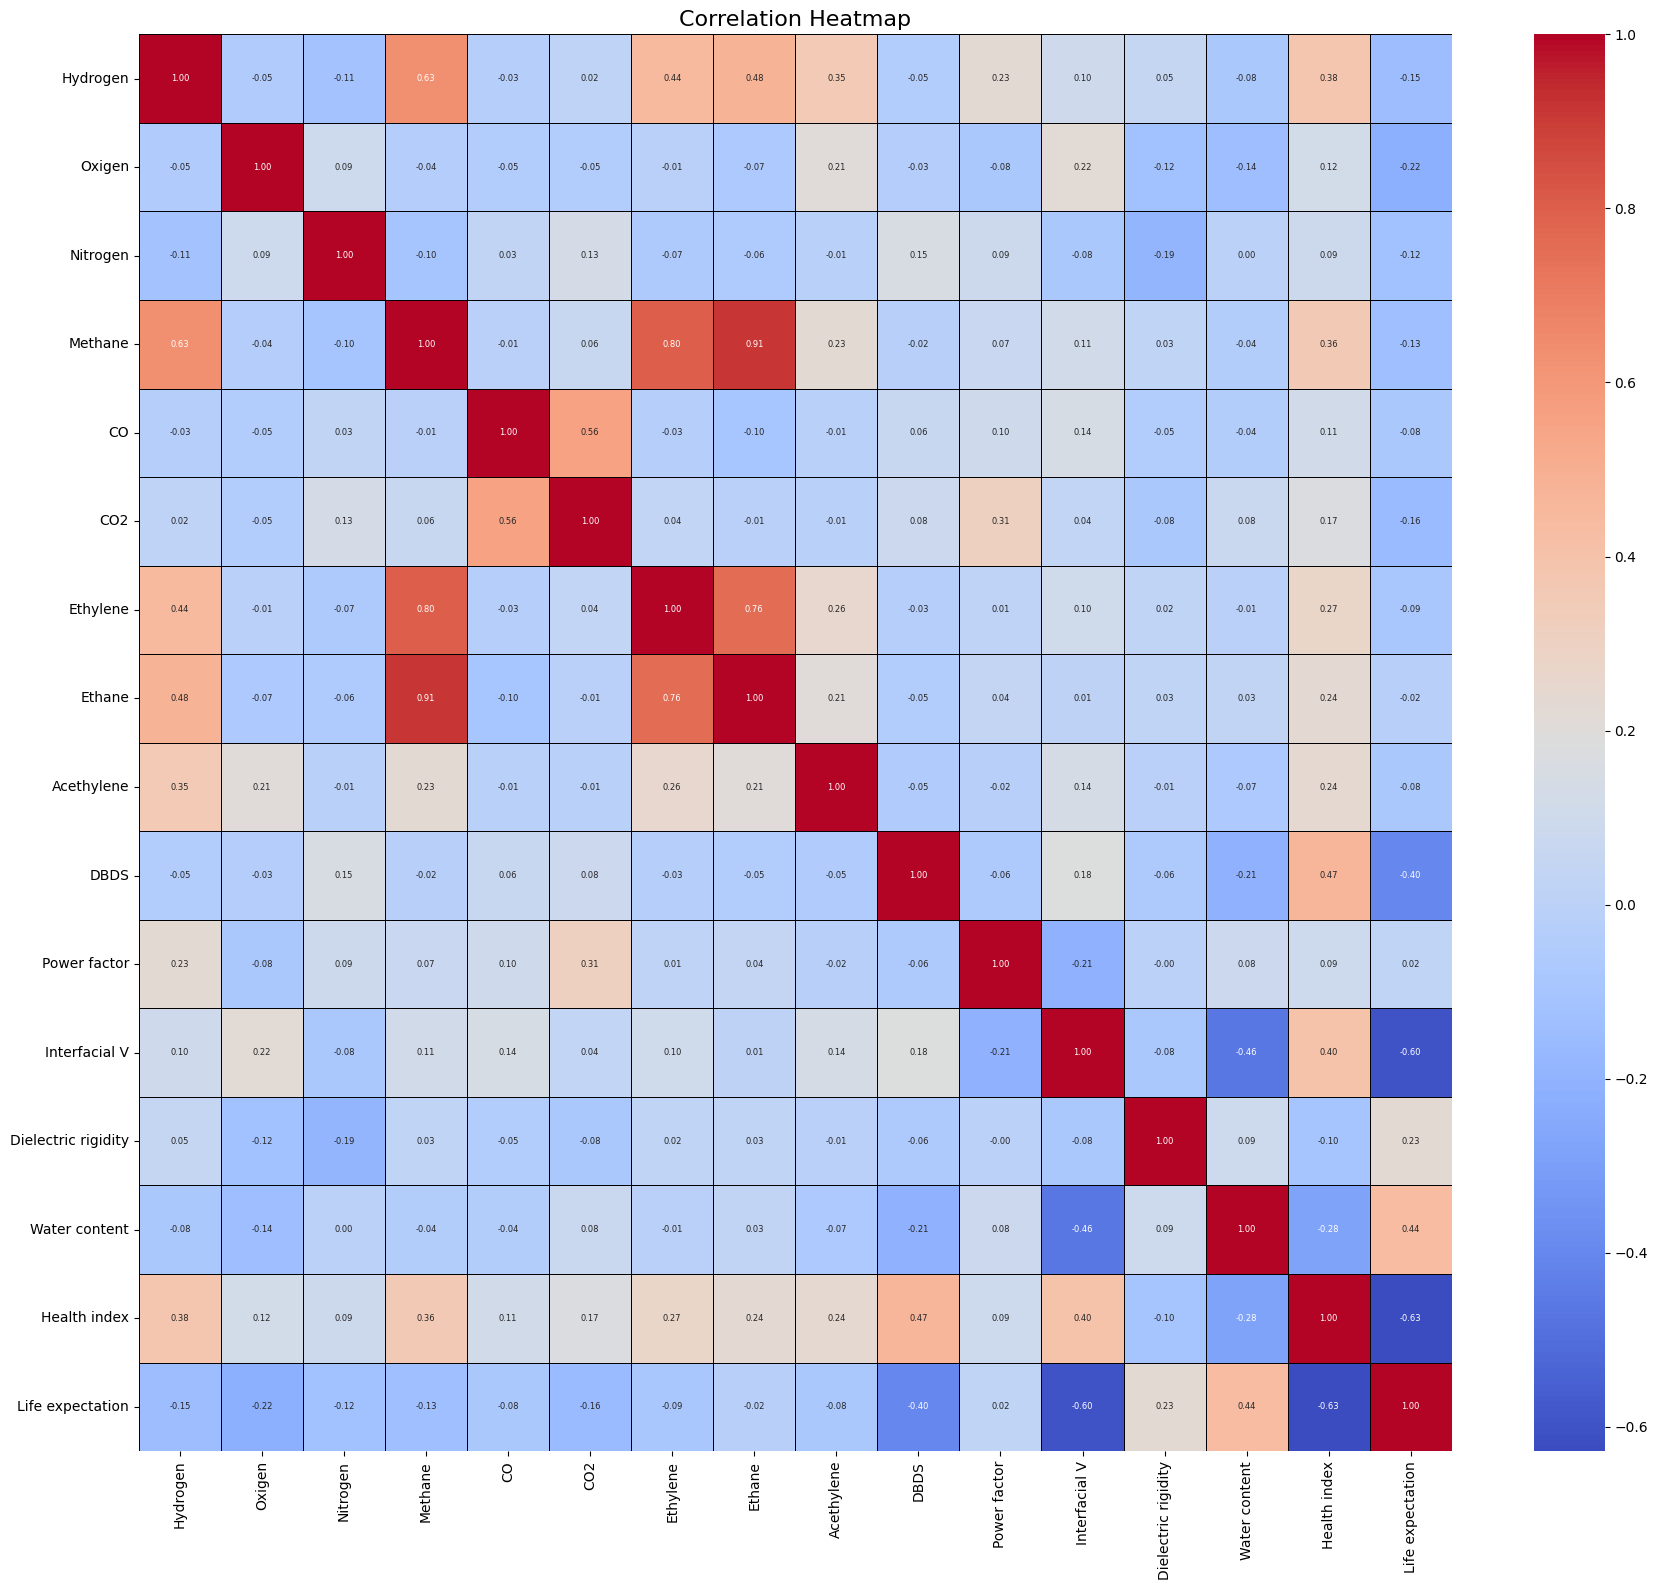

In [5]:
# Correlation Heatmap
hm = df.corr(numeric_only=True)
plt.figure(figsize=(18, 16))
sns.heatmap(hm, annot=True, cmap='coolwarm', linewidths=0.5,
            linecolor='black', fmt=".2f", annot_kws={'fontsize': 6})
plt.title('Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

## 2. Preprocessing & Train/Test Split

In [6]:
DROP_COLS = ['Life expectation']

df_clean     = df.dropna(subset=[TARGET_COLUMN]).copy()
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
df_clean[numeric_cols] = df_clean[numeric_cols].fillna(df_clean[numeric_cols].median())

X = df_clean.drop(columns=[TARGET_COLUMN] + DROP_COLS, errors='ignore')
X = X.select_dtypes(include=[np.number])
y = df_clean[TARGET_COLUMN]

# Specific feature subset for SVR and Polynomial
FEATURE_COLS = ['Hydrogen', 'Oxigen', 'Nitrogen', 'Methane', 'CO', 'CO2',
                'Ethylene', 'Ethane', 'Acethylene', 'DBDS',
                'Power factor', 'Interfacial V', 'Dielectric rigidity', 'Water content']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Features  : {X.shape[1]}")
print(f"Train rows: {X_train.shape[0]}")
print(f"Test  rows: {X_test.shape[0]}")

Features  : 14
Train rows: 376
Test  rows: 94


## 3. Helper Functions

In [7]:
def evaluate(name, y_tr, yp_tr, y_te, yp_te):
    """Compute metrics, print summary, return result dict."""
    mae_te  = mean_absolute_error(y_te, yp_te)
    mse_te  = mean_squared_error(y_te,  yp_te)
    rmse_te = np.sqrt(mse_te)
    r2_te   = r2_score(y_te, yp_te)
    mae_tr  = mean_absolute_error(y_tr, yp_tr)
    mse_tr  = mean_squared_error(y_tr,  yp_tr)
    rmse_tr = np.sqrt(mse_tr)
    r2_tr   = r2_score(y_tr, yp_tr)

    if r2_tr < 0.6 and r2_te < 0.6:
        condition = "Underfitting"
    elif r2_tr - r2_te > 0.15:
        condition = "Overfitting"
    else:
        condition = "Best Fitting"

    print(f"{'─'*55}")
    print(f"  {name}")
    print(f"{'─'*55}")
    print(f"  Train  →  R²={r2_tr:.4f}  MAE={mae_tr:.4f}  RMSE={rmse_tr:.4f}")
    print(f"  Test   →  R²={r2_te:.4f}  MAE={mae_te:.4f}  RMSE={rmse_te:.4f}")
    print(f"  Condition: {condition}")
    return {'Model': name, 'Train_R2': round(r2_tr,4), 'Test_R2': round(r2_te,4),
            'Test_MAE': round(mae_te,4), 'Test_MSE': round(mse_te,4),
            'Test_RMSE': round(rmse_te,4), 'Condition': condition}

def parity_plot(name, y_te, yp_te):
    fig, ax = plt.subplots(figsize=(6,5))
    ax.scatter(y_te, yp_te, alpha=0.6, edgecolors='k', linewidths=0.3)
    lims = [min(y_te.min(), yp_te.min()), max(y_te.max(), yp_te.max())]
    ax.plot(lims, lims, 'r--', lw=2, label='Perfect fit')
    ax.set_xlabel("Actual Health Index"); ax.set_ylabel("Predicted Health Index")
    ax.set_title(f"{name} – Actual vs Predicted"); ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

def fitting_bar(name, r2_tr, r2_te, condition):
    fig, ax = plt.subplots(figsize=(5,4))
    bars = ax.bar(["Train R²", "Test R²"], [r2_tr, r2_te], color=['steelblue','darkorange'])
    ax.set_ylim(0, 1.1); ax.set_ylabel("R² Score")
    ax.set_title(f"{name} – {condition}")
    for bar, val in zip(bars, [r2_tr, r2_te]):
        ax.text(bar.get_x()+bar.get_width()/2, val+0.02, f"{val:.4f}", ha='center', fontsize=10)
    plt.tight_layout(); plt.show()

results = []
print("Helper functions defined.")

Helper functions defined.


## 4. Model 1 – Simple Linear Regression

Most correlated feature with 'Health index': 'DBDS'
Correlation: 0.4688

Regression equation: Health index = 0.1814 × DBDS + 24.4146
───────────────────────────────────────────────────────
  Simple Linear Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.2054  MAE=13.0931  RMSE=15.6022
  Test   →  R²=0.2651  MAE=13.0016  RMSE=15.8652
  Condition: Underfitting


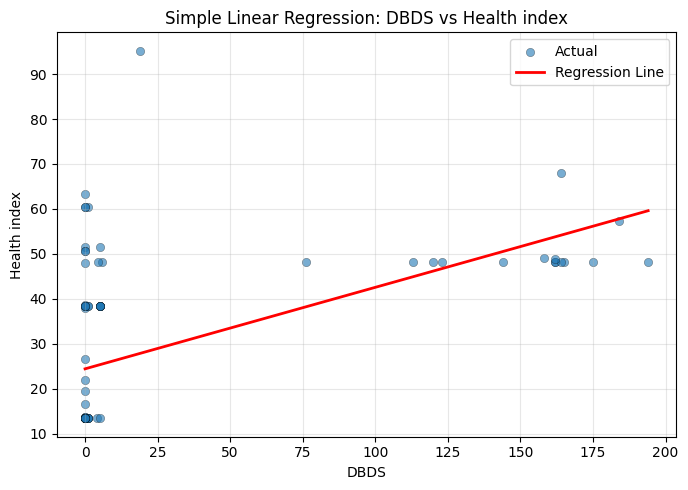

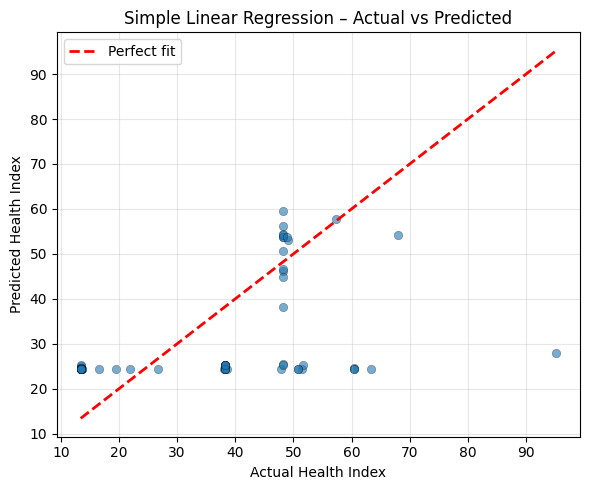

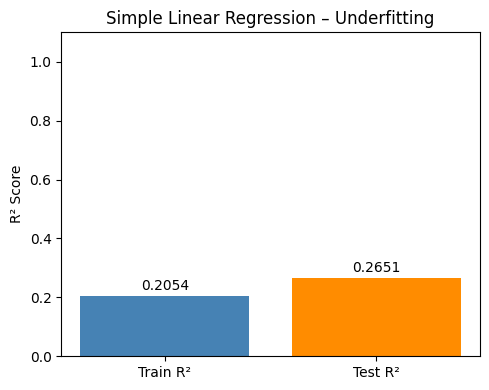

In [8]:
# ── Simple Linear Regression ──
# Uses the single feature most correlated with the target

corr_with_target = df_clean[X.columns].corrwith(y).abs().sort_values(ascending=False)
best_feature = corr_with_target.index[0]
print(f"Most correlated feature with '{TARGET_COLUMN}': '{best_feature}'")
print(f"Correlation: {corr_with_target.iloc[0]:.4f}")

X_slr = df_clean[[best_feature]].copy()
X_slr_train, X_slr_test, y_slr_train, y_slr_test = train_test_split(
    X_slr, y, test_size=0.2, random_state=42)

slr_model = LinearRegression()
slr_model.fit(X_slr_train, y_slr_train)
yp_te_slr = slr_model.predict(X_slr_test)
yp_tr_slr = slr_model.predict(X_slr_train)

print(f"\nRegression equation: {TARGET_COLUMN} = {slr_model.coef_[0]:.4f} × {best_feature} + {slr_model.intercept_:.4f}")

res_slr = evaluate("Simple Linear Regression", y_slr_train, yp_tr_slr, y_slr_test, yp_te_slr)
results.append(res_slr)

# Regression line plot
x_line = np.linspace(X_slr_test[best_feature].min(), X_slr_test[best_feature].max(), 200)
y_line = slr_model.coef_[0] * x_line + slr_model.intercept_

plt.figure(figsize=(7, 5))
plt.scatter(X_slr_test[best_feature], y_slr_test, alpha=0.6, edgecolors='k',
            linewidths=0.3, label='Actual')
plt.plot(x_line, y_line, color='red', lw=2, label='Regression Line')
plt.xlabel(best_feature); plt.ylabel(TARGET_COLUMN)
plt.title(f"Simple Linear Regression: {best_feature} vs {TARGET_COLUMN}")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

parity_plot("Simple Linear Regression", y_slr_test, yp_te_slr)
fitting_bar("Simple Linear Regression", res_slr['Train_R2'], res_slr['Test_R2'], res_slr['Condition'])

## 5. Model 2 – Multiple Linear Regression

───────────────────────────────────────────────────────
  Multiple Linear Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.5046  MAE=9.4591  RMSE=12.3192
  Test   →  R²=0.4956  MAE=9.6272  RMSE=13.1437
  Condition: Underfitting

Top 10 coefficients (by absolute value):
            Feature  Coefficient
      Interfacial V     0.716066
       Power factor     0.239533
Dielectric rigidity    -0.198280
               DBDS     0.159444
      Water content    -0.037371
             Ethane    -0.011502
            Methane     0.007848
         Acethylene     0.002930
           Hydrogen     0.002436
           Ethylene     0.000500
Intercept: 0.8426


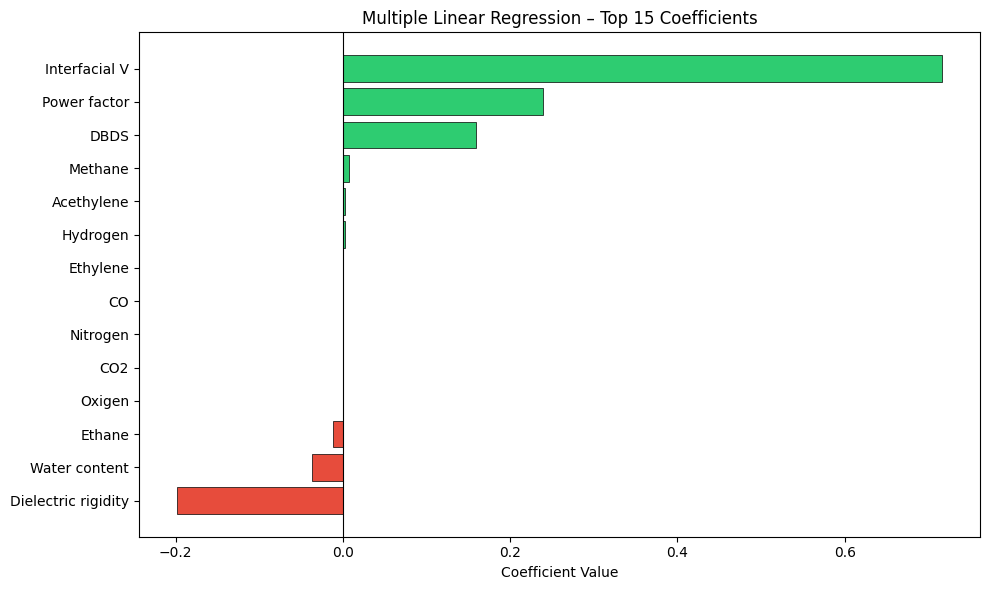

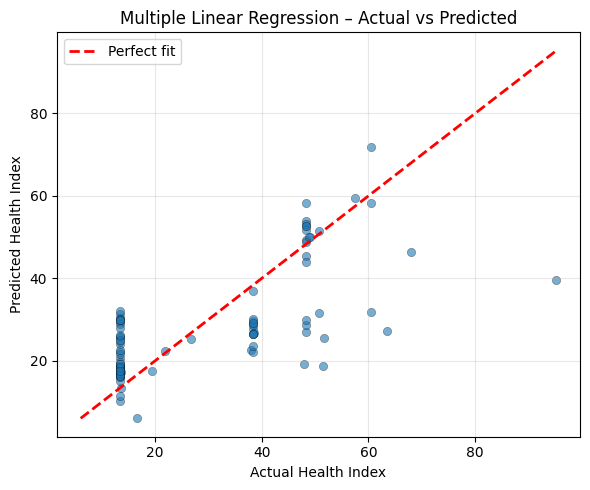

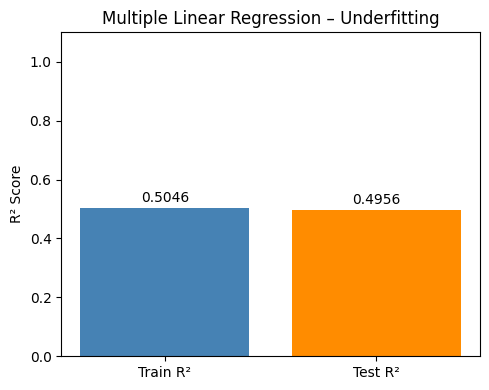

In [9]:
# ── Multiple Linear Regression ──
# Uses all numeric features (same X_train / X_test as all other models)

mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)
yp_te_mlr = mlr_model.predict(X_test)
yp_tr_mlr = mlr_model.predict(X_train)

res_mlr = evaluate("Multiple Linear Regression", y_train, yp_tr_mlr, y_test, yp_te_mlr)
results.append(res_mlr)

# Coefficient table
coef_mlr = pd.DataFrame({'Feature': X.columns, 'Coefficient': mlr_model.coef_}
                        ).sort_values('Coefficient', key=abs, ascending=False)
print("\nTop 10 coefficients (by absolute value):")
print(coef_mlr.head(10).to_string(index=False))
print(f"Intercept: {mlr_model.intercept_:.4f}")

# Bar chart of coefficients
plt.figure(figsize=(10, 6))
top_coef = coef_mlr.head(15).sort_values('Coefficient')
colors_coef = ['#e74c3c' if v < 0 else '#2ecc71' for v in top_coef['Coefficient']]
plt.barh(top_coef['Feature'], top_coef['Coefficient'], color=colors_coef, edgecolor='k', linewidth=0.5)
plt.xlabel('Coefficient Value'); plt.title('Multiple Linear Regression – Top 15 Coefficients')
plt.axvline(0, color='black', linewidth=0.8); plt.tight_layout(); plt.show()

parity_plot("Multiple Linear Regression", y_test, yp_te_mlr)
fitting_bar("Multiple Linear Regression", res_mlr['Train_R2'], res_mlr['Test_R2'], res_mlr['Condition'])

## 6. Model 3 – Ridge Regression

Alpha tuning (5-Fold CV):
  alpha=0.001    avg_R²=-997776266648941353629269360640.0000  std=1241613722491685287238819643392.0000
  alpha=0.01     avg_R²=-997774764371853040117899853824.0000  std=1241607639899396483356431482880.0000
  alpha=0.1      avg_R²=-997760138512816872670732746752.0000  std=1241547465800317472076264898560.0000
  alpha=1        avg_R²=-997651142596451965803150966784.0000  std=1241007185909763199989073313792.0000
  alpha=10       avg_R²=-998810208164694802099467190272.0000  std=1239437235059718437984614219776.0000
  alpha=100      avg_R²=-1037189753548876234085869027328.0000  std=1277621152137125889813919039488.0000
  alpha=1000     avg_R²=-1246820839596848665371892252672.0000  std=1527760759437759029067758174208.0000

Best alpha: 1  (CV R²=-997651142596451965803150966784.0000)
───────────────────────────────────────────────────────
  Ridge Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.5046  MAE=9.4619  RMSE=12.3193
  Test   → 

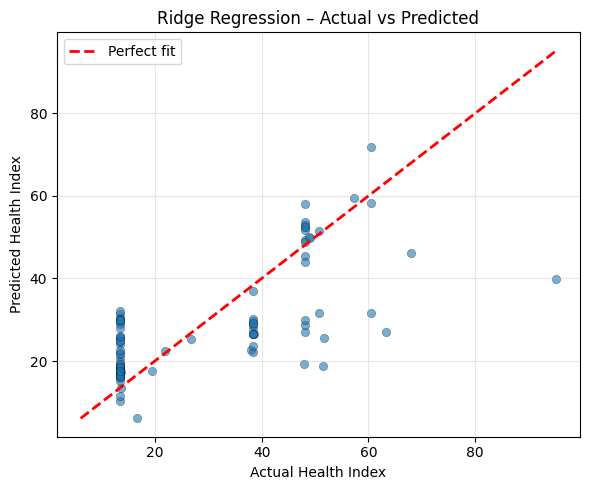

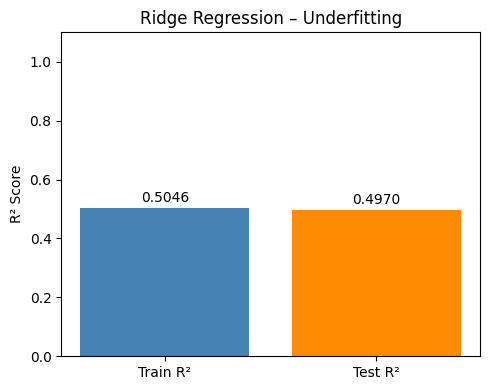

In [11]:
# ── Ridge Regression ──
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

print("Alpha tuning (5-Fold CV):")
# Initialize with the first alpha's performance to ensure best_alpha_ridge is set
m_initial = make_pipeline(StandardScaler(), Ridge(alpha=alphas[0], random_state=42))
s_initial = cross_val_score(m_initial, X, y, cv=5, scoring='r2')
best_alpha_ridge = alphas[0]
best_r2_ridge = s_initial.mean()

print(f"  alpha={alphas[0]:<7}  avg_R²={s_initial.mean():.4f}  std={s_initial.std():.4f}")

for a in alphas[1:]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a, random_state=42))
    s = cross_val_score(m, X, y, cv=5, scoring='r2')
    print(f"  alpha={a:<7}  avg_R²={s.mean():.4f}  std={s.std():.4f}")
    if s.mean() > best_r2_ridge:
        best_r2_ridge = s.mean()
        best_alpha_ridge = a

print(f"\nBest alpha: {best_alpha_ridge}  (CV R²={best_r2_ridge:.4f})")

ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha_ridge, random_state=42))
ridge_model.fit(X_train, y_train)
yp_te_ridge = ridge_model.predict(X_test)
yp_tr_ridge = ridge_model.predict(X_train)

res_ridge = evaluate("Ridge Regression", y_train, yp_tr_ridge, y_test, yp_te_ridge)
results.append(res_ridge)
parity_plot("Ridge Regression", y_test, yp_te_ridge)
fitting_bar("Ridge Regression", res_ridge['Train_R2'], res_ridge['Test_R2'], res_ridge['Condition'])

## 7. Model 4 – Lasso Regression

Best alpha (LassoCV): 0.911987
───────────────────────────────────────────────────────
  Lasso Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.4798  MAE=10.1251  RMSE=12.6241
  Test   →  R²=0.4529  MAE=10.1457  RMSE=13.6888
  Condition: Underfitting
Features removed (coef=0): 5


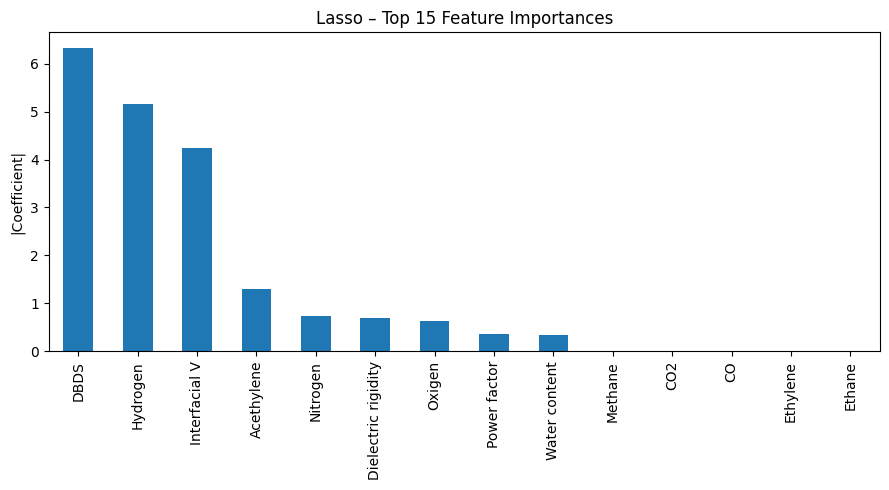

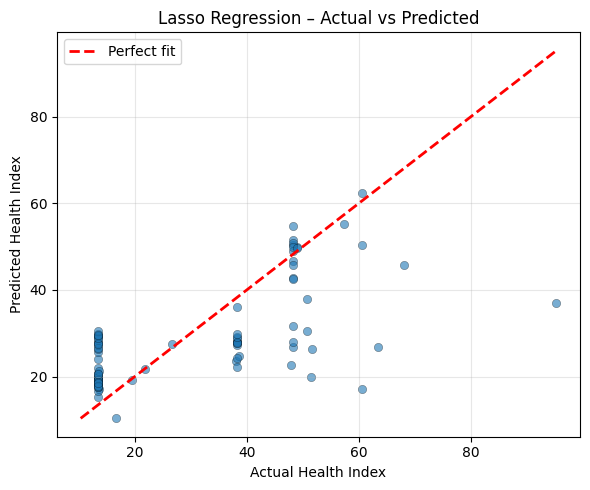

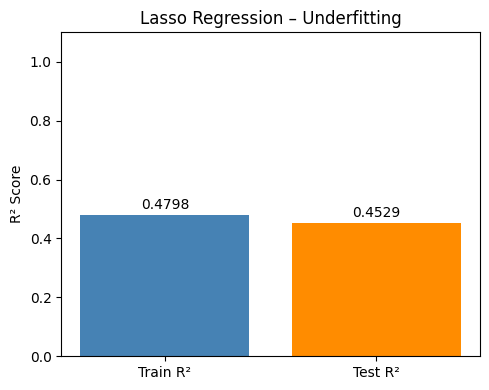

In [12]:
# ── Lasso Regression ──
scaler_lasso = StandardScaler()
X_tr_sc = scaler_lasso.fit_transform(X_train)
X_te_sc = scaler_lasso.transform(X_test)

lasso_cv_model = LassoCV(cv=5, random_state=42, max_iter=20000)
lasso_cv_model.fit(X_tr_sc, y_train)
best_alpha_lasso = lasso_cv_model.alpha_
print(f"Best alpha (LassoCV): {best_alpha_lasso:.6f}")

lasso_model = Lasso(alpha=best_alpha_lasso, max_iter=20000)
lasso_model.fit(X_tr_sc, y_train)
yp_te_lasso = lasso_model.predict(X_te_sc)
yp_tr_lasso = lasso_model.predict(X_tr_sc)

res_lasso = evaluate("Lasso Regression", y_train, yp_tr_lasso, y_test, yp_te_lasso)
results.append(res_lasso)

# Feature importance
coef_lasso = pd.Series(lasso_model.coef_, index=X.columns).abs().sort_values(ascending=False)
print(f"Features removed (coef=0): {(lasso_model.coef_ == 0).sum()}")
coef_lasso.head(15).plot(kind='bar', figsize=(9,5),
                          title="Lasso – Top 15 Feature Importances")
plt.ylabel("|Coefficient|"); plt.tight_layout(); plt.show()

parity_plot("Lasso Regression", y_test, yp_te_lasso)
fitting_bar("Lasso Regression", res_lasso['Train_R2'], res_lasso['Test_R2'], res_lasso['Condition'])

## 8. Model 5 – Elastic Net Regression

───────────────────────────────────────────────────────
  Elastic Net Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.5029  MAE=9.5534  RMSE=12.3404
  Test   →  R²=0.5194  MAE=9.5501  RMSE=12.8295
  Condition: Underfitting
Top 10 Elastic Net coefficients:
      Feature  Coefficient
         DBDS     6.616222
     Hydrogen     4.688690
Interfacial V     4.183781
      Methane     2.311340
   Acethylene     1.874461
     Nitrogen     1.347432
 Power factor     1.241244
       Oxigen     1.082472
     Ethylene     0.432229
          CO2     0.235226
Zero coefficients: 0


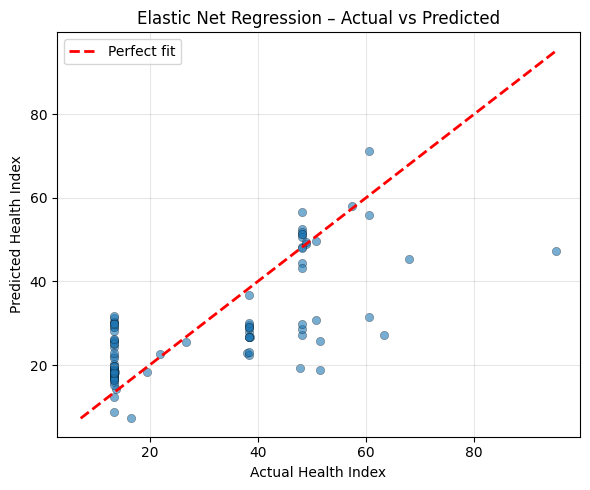

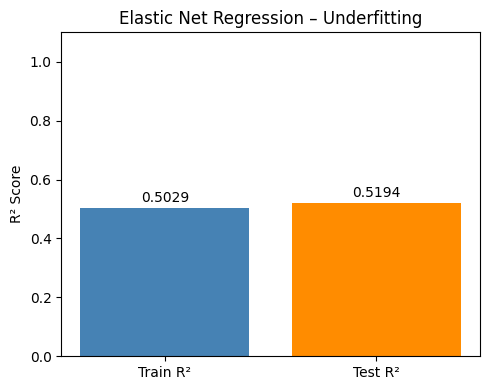

In [13]:
# ── Elastic Net Regression ──
scaler_en = StandardScaler()
X_tr_en = scaler_en.fit_transform(X_train)
X_te_en = scaler_en.transform(X_test)

en_model = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42)
en_model.fit(X_tr_en, y_train)
yp_te_en = en_model.predict(X_te_en)
yp_tr_en = en_model.predict(X_tr_en)

res_en = evaluate("Elastic Net Regression", y_train, yp_tr_en, y_test, yp_te_en)
results.append(res_en)

coef_en = pd.DataFrame({'Feature': X.columns, 'Coefficient': en_model.coef_}
                       ).sort_values('Coefficient', ascending=False)
print("Top 10 Elastic Net coefficients:")
print(coef_en.head(10).to_string(index=False))
print(f"Zero coefficients: {(coef_en['Coefficient']==0).sum()}")

parity_plot("Elastic Net Regression", y_test, yp_te_en)
fitting_bar("Elastic Net Regression", res_en['Train_R2'], res_en['Test_R2'], res_en['Condition'])

## 9. Model 6 – Polynomial Regression (degree=2)

Polynomial features (degree=2): 119
───────────────────────────────────────────────────────
  Polynomial Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.7882  MAE=5.6905  RMSE=8.0545
  Test   →  R²=-0.1210  MAE=12.6020  RMSE=19.5938
  Condition: Overfitting


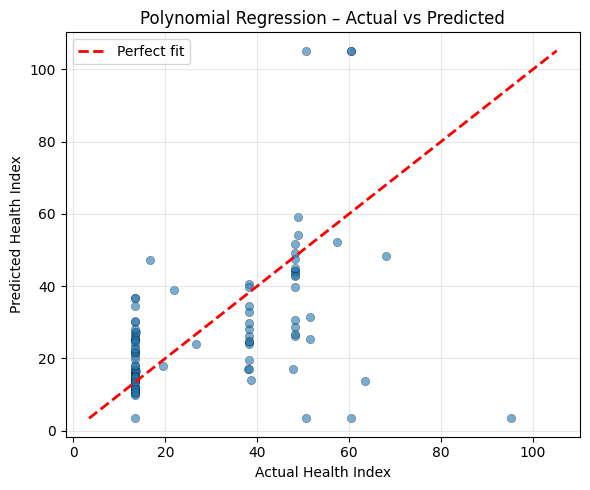

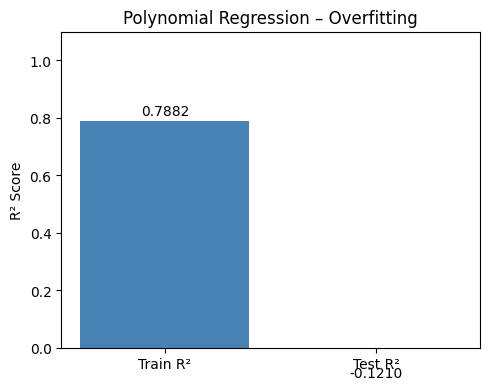

In [14]:
# ── Polynomial Regression (degree=2) ──
# Note: Degree is kept at 2 to avoid overfitting / numerical instability.
# Features are scaled before polynomial expansion for stability.

X_poly_df = df_clean[FEATURE_COLS].copy().fillna(df_clean[FEATURE_COLS].median())

Xp_train, Xp_test, yp_train_poly, yp_test_poly = train_test_split(
    X_poly_df, y, test_size=0.2, random_state=42)

# Scale BEFORE polynomial expansion to prevent huge coefficient values
scaler_poly = StandardScaler()
Xp_train_sc = scaler_poly.fit_transform(Xp_train)
Xp_test_sc  = scaler_poly.transform(Xp_test)

poly = PolynomialFeatures(degree=2, include_bias=False)
Xp_train_poly = poly.fit_transform(Xp_train_sc)
Xp_test_poly  = poly.transform(Xp_test_sc)
print(f"Polynomial features (degree=2): {Xp_train_poly.shape[1]}")

poly_model = LinearRegression()
poly_model.fit(Xp_train_poly, yp_train_poly)
yp_te_poly = poly_model.predict(Xp_test_poly)
yp_tr_poly = poly_model.predict(Xp_train_poly)

# Clip extreme predictions to y range to avoid matplotlib size error
y_min, y_max = y.min() - 10, y.max() + 10
yp_te_poly = np.clip(yp_te_poly, y_min, y_max)
yp_tr_poly = np.clip(yp_tr_poly, y_min, y_max)

res_poly = evaluate("Polynomial Regression", yp_train_poly, yp_tr_poly, yp_test_poly, yp_te_poly)
results.append(res_poly)
parity_plot("Polynomial Regression", yp_test_poly, yp_te_poly)
fitting_bar("Polynomial Regression", res_poly['Train_R2'], res_poly['Test_R2'], res_poly['Condition'])

## 10. Model 7 – Support Vector Regression (SVR)

───────────────────────────────────────────────────────
  SVR (RBF)
───────────────────────────────────────────────────────
  Train  →  R²=0.8042  MAE=3.6968  RMSE=7.7447
  Test   →  R²=0.5284  MAE=8.2826  RMSE=12.7089
  Condition: Overfitting


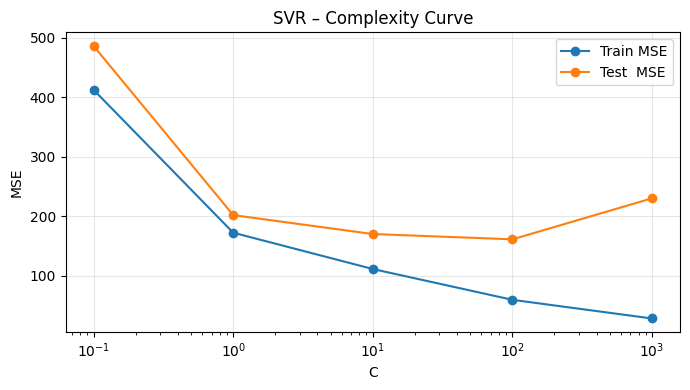

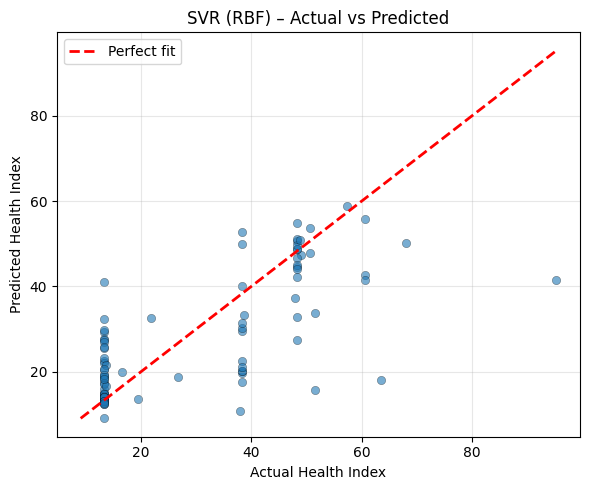

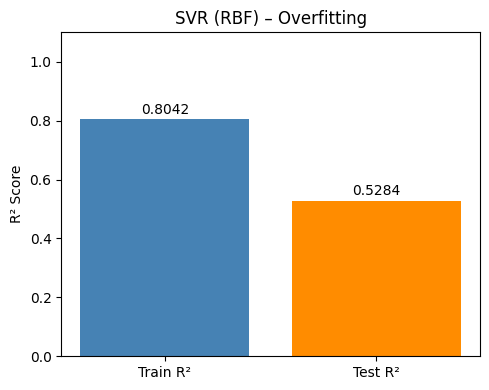

In [15]:
# ── SVR ──
X_svr_df = df_clean[FEATURE_COLS].copy().fillna(df_clean[FEATURE_COLS].median())
Xsvr_train, Xsvr_test, ysvr_train, ysvr_test = train_test_split(
    X_svr_df, y, test_size=0.2, random_state=42)

scaler_svr = StandardScaler()
Xsvr_tr_sc = scaler_svr.fit_transform(Xsvr_train)
Xsvr_te_sc = scaler_svr.transform(Xsvr_test)

svr_model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svr_model.fit(Xsvr_tr_sc, ysvr_train)
yp_te_svr = svr_model.predict(Xsvr_te_sc)
yp_tr_svr = svr_model.predict(Xsvr_tr_sc)

res_svr = evaluate("SVR (RBF)", ysvr_train, yp_tr_svr, ysvr_test, yp_te_svr)
results.append(res_svr)

# C complexity curve
C_values = [0.1, 1, 10, 100, 1000]
train_mse_svr, test_mse_svr = [], []
for C in C_values:
    m = SVR(kernel='rbf', C=C, gamma=0.1)
    m.fit(Xsvr_tr_sc, ysvr_train)
    train_mse_svr.append(mean_squared_error(ysvr_train, m.predict(Xsvr_tr_sc)))
    test_mse_svr.append(mean_squared_error(ysvr_test,  m.predict(Xsvr_te_sc)))

plt.figure(figsize=(7,4))
plt.plot(C_values, train_mse_svr, marker='o', label='Train MSE')
plt.plot(C_values, test_mse_svr,  marker='o', label='Test  MSE')
plt.xscale('log'); plt.xlabel('C'); plt.ylabel('MSE')
plt.title('SVR – Complexity Curve'); plt.legend(); plt.grid(True,alpha=0.3)
plt.tight_layout(); plt.show()

parity_plot("SVR (RBF)", ysvr_test, yp_te_svr)
fitting_bar("SVR (RBF)", res_svr['Train_R2'], res_svr['Test_R2'], res_svr['Condition'])

## 11. Model 8 – KNN Regression

Best KNN params: {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'distance'}
Best CV R²     : 0.4809
───────────────────────────────────────────────────────
  KNN Regression
───────────────────────────────────────────────────────
  Train  →  R²=1.0000  MAE=0.0000  RMSE=0.0000
  Test   →  R²=0.5332  MAE=8.4592  RMSE=12.6445
  Condition: Overfitting


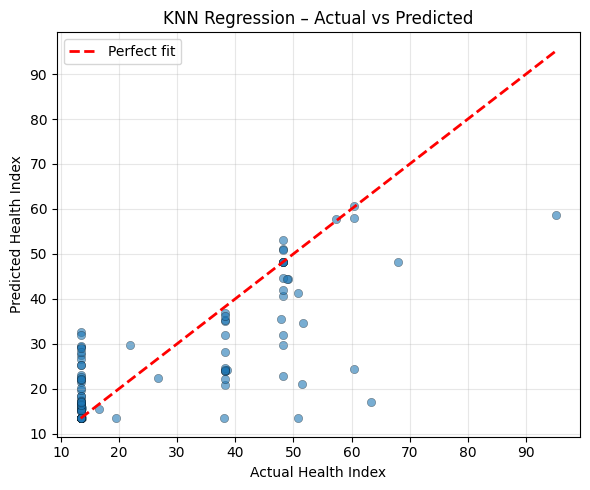

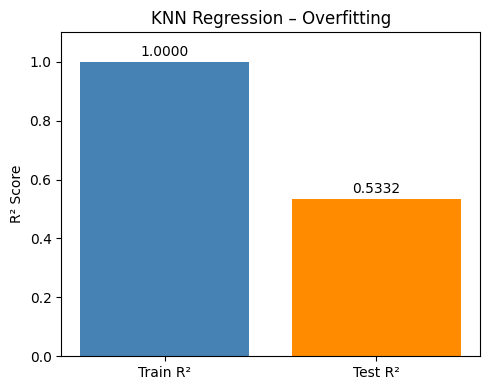

In [16]:
# ── KNN Regression ──
scaler_knn = StandardScaler()
X_knn_tr = scaler_knn.fit_transform(X_train)
X_knn_te = scaler_knn.transform(X_test)

knn_params = {"n_neighbors": [3,5,7,9,11,15],
              "weights"    : ["uniform","distance"],
              "metric"     : ["euclidean","manhattan","minkowski"]}

grid_knn = GridSearchCV(KNeighborsRegressor(), knn_params,
                        scoring='r2', cv=5, n_jobs=-1, verbose=0)
grid_knn.fit(X_knn_tr, y_train)
best_knn = grid_knn.best_estimator_
print("Best KNN params:", grid_knn.best_params_)
print("Best CV R²     :", round(grid_knn.best_score_, 4))

yp_te_knn = best_knn.predict(X_knn_te)
yp_tr_knn = best_knn.predict(X_knn_tr)

res_knn = evaluate("KNN Regression", y_train, yp_tr_knn, y_test, yp_te_knn)
results.append(res_knn)
parity_plot("KNN Regression", y_test, yp_te_knn)
fitting_bar("KNN Regression", res_knn['Train_R2'], res_knn['Test_R2'], res_knn['Condition'])

## 12. Model 9 – Decision Tree Regression

Best DT params: {'max_depth': 4, 'min_samples_leaf': 5}
Best CV R²    : 0.5443
───────────────────────────────────────────────────────
  Decision Tree Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.7475  MAE=5.7028  RMSE=8.7945
  Test   →  R²=0.7641  MAE=6.2245  RMSE=8.9876
  Condition: Best Fitting


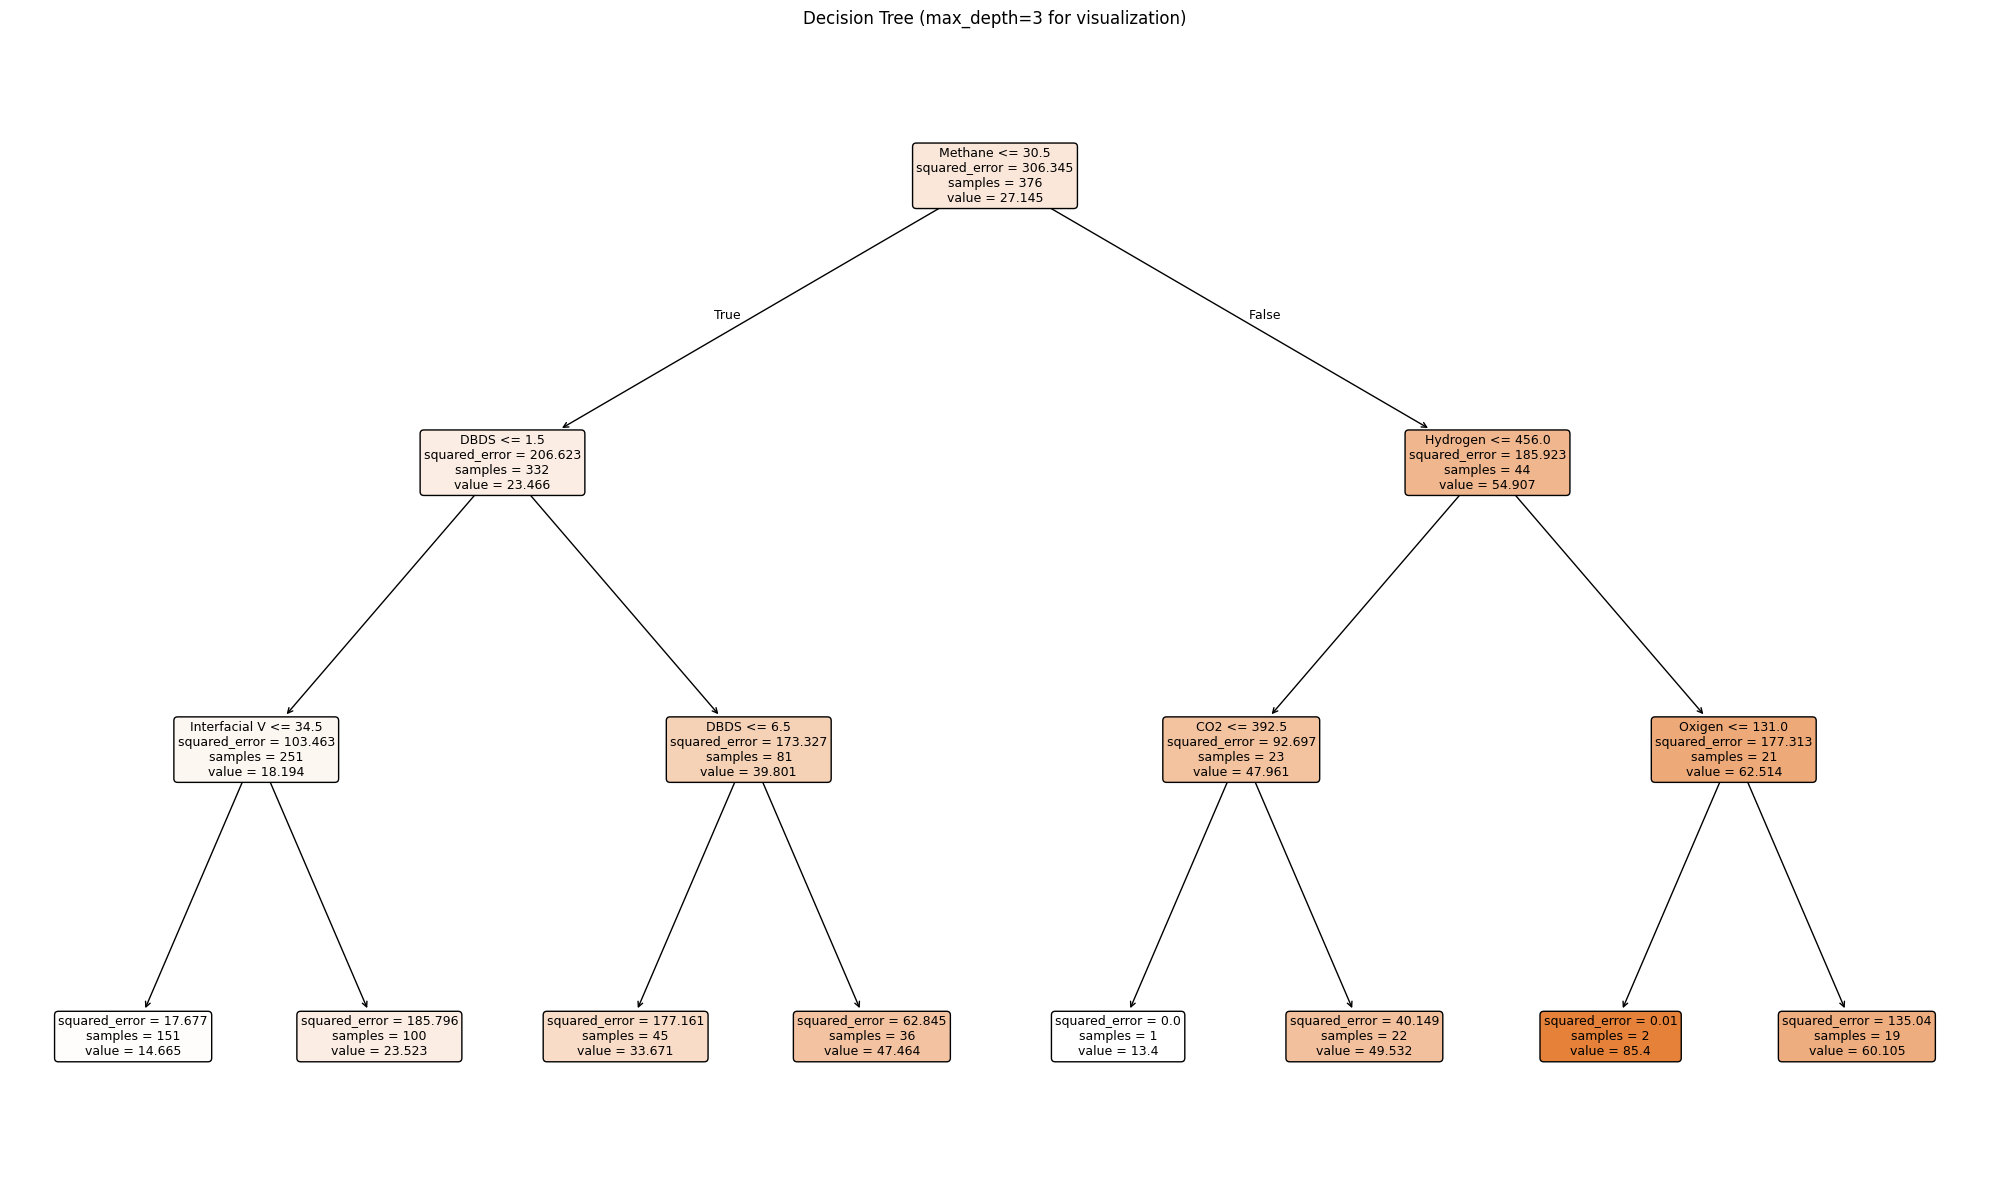

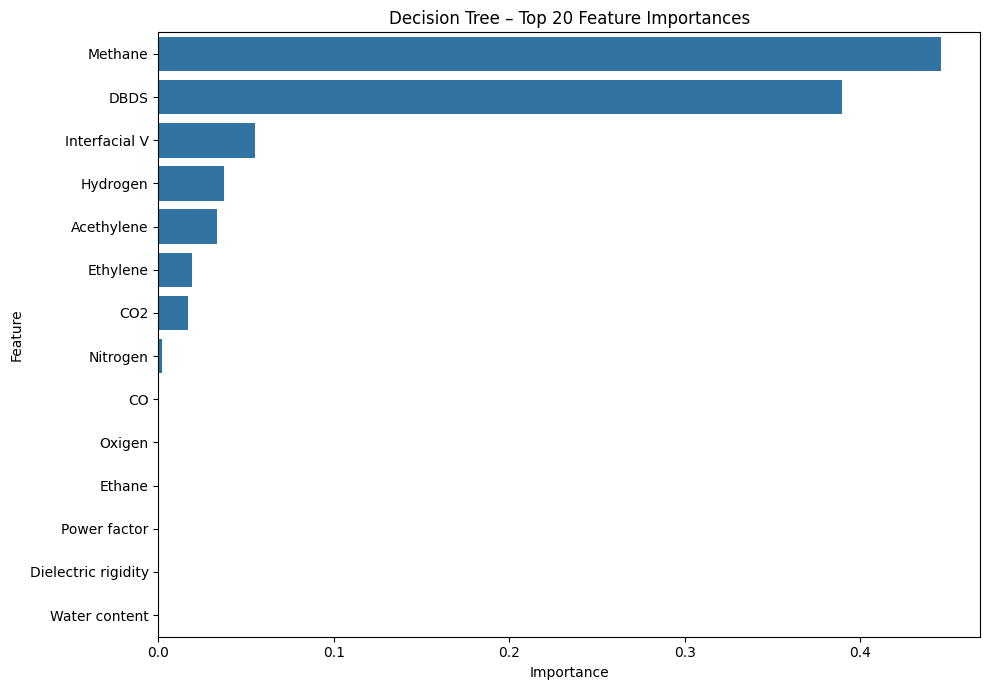

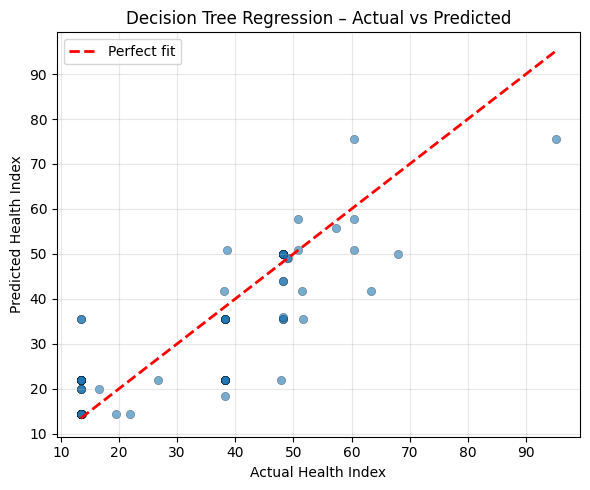

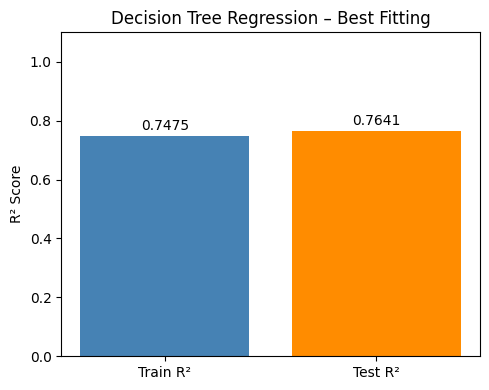

In [17]:
# ── Decision Tree Regression ──
dt_params = {'max_depth': [4,8,12,16,20], 'min_samples_leaf': [1,5,10]}
grid_dt = GridSearchCV(DecisionTreeRegressor(random_state=42), dt_params,
                       scoring='r2', cv=5, n_jobs=-1, verbose=0)
grid_dt.fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
print("Best DT params:", grid_dt.best_params_)
print("Best CV R²    :", round(grid_dt.best_score_, 4))

yp_te_dt = best_dt.predict(X_test)
yp_tr_dt = best_dt.predict(X_train)

res_dt = evaluate("Decision Tree Regression", y_train, yp_tr_dt, y_test, yp_te_dt)
results.append(res_dt)

# Simplified tree visualization
simple_dt = DecisionTreeRegressor(max_depth=3, random_state=42)
simple_dt.fit(X_train, y_train)
plt.figure(figsize=(20,12))
plot_tree(simple_dt, feature_names=X.columns.tolist(), filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=3 for visualization)"); plt.tight_layout(); plt.show()

# Feature importances
fi_dt = pd.DataFrame({'Feature': X.columns,
                      'Importance': best_dt.feature_importances_}).sort_values('Importance', ascending=False)
plt.figure(figsize=(10,7))
sns.barplot(x='Importance', y='Feature', data=fi_dt.head(20))
plt.title("Decision Tree – Top 20 Feature Importances"); plt.tight_layout(); plt.show()

parity_plot("Decision Tree Regression", y_test, yp_te_dt)
fitting_bar("Decision Tree Regression", res_dt['Train_R2'], res_dt['Test_R2'], res_dt['Condition'])

## 13. Model 10 – Random Forest Regression

Best RF params: {'max_depth': 10, 'max_features': 0.5, 'n_estimators': 300}
Best CV R²    : 0.6647
───────────────────────────────────────────────────────
  Random Forest Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.9453  MAE=2.6971  RMSE=4.0946
  Test   →  R²=0.7638  MAE=6.0380  RMSE=8.9939
  Condition: Overfitting
Top 10 RF features:
DBDS             0.259986
Methane          0.193951
Hydrogen         0.104930
Interfacial V    0.103522
Acethylene       0.069134
Ethylene         0.043196
Water content    0.034761
Oxigen           0.031099
CO               0.030153
Power factor     0.030041


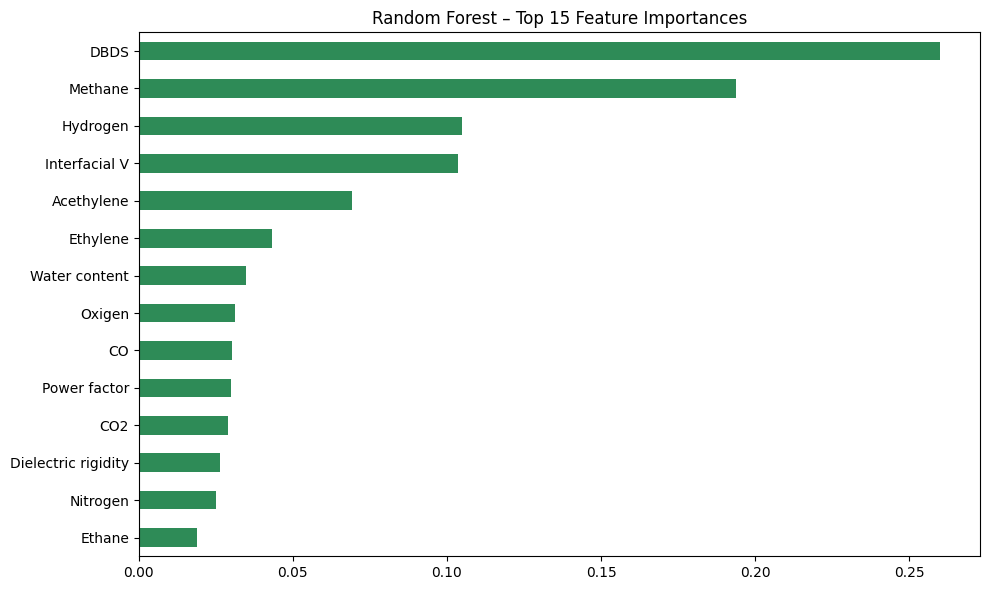

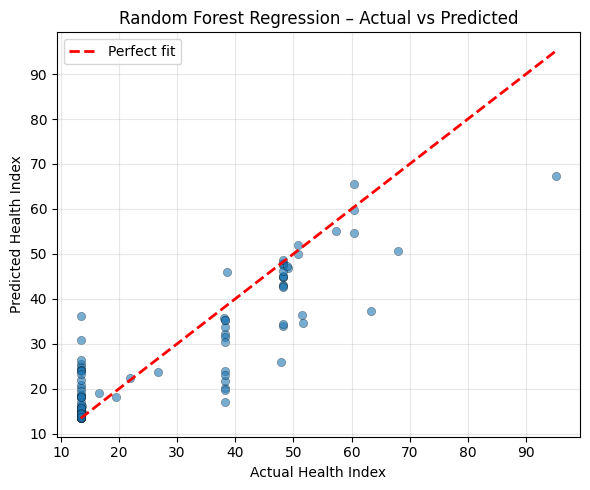

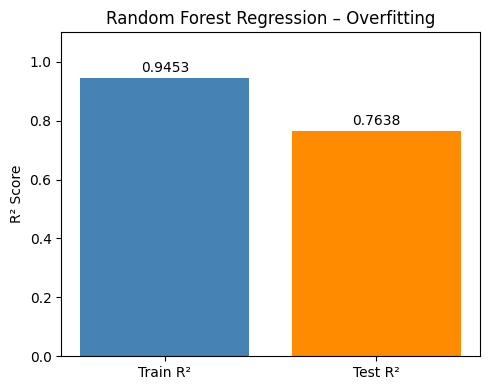

In [18]:
# ── Random Forest Regression ──
rf_params = {"n_estimators": [100,200,300],
             "max_depth"   : [None,10,20],
             "max_features": ["sqrt","log2",0.5]}

grid_rf = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                       rf_params, scoring='r2', cv=5, n_jobs=-1, verbose=0)
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_
print("Best RF params:", grid_rf.best_params_)
print("Best CV R²    :", round(grid_rf.best_score_, 4))

yp_te_rf = best_rf.predict(X_test)
yp_tr_rf = best_rf.predict(X_train)

res_rf = evaluate("Random Forest Regression", y_train, yp_tr_rf, y_test, yp_te_rf)
results.append(res_rf)

fi_rf = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 10 RF features:"); print(fi_rf.head(10).to_string())

plt.figure(figsize=(10,6))
fi_rf.head(15).sort_values().plot(kind='barh', color='seagreen')
plt.title("Random Forest – Top 15 Feature Importances"); plt.tight_layout(); plt.show()

parity_plot("Random Forest Regression", y_test, yp_te_rf)
fitting_bar("Random Forest Regression", res_rf['Train_R2'], res_rf['Test_R2'], res_rf['Condition'])

## 14. Model 11 – AdaBoost Regression

Best AdaBoost params: {'learning_rate': 0.01, 'n_estimators': 300}
Best CV R²          : 0.6357
───────────────────────────────────────────────────────
  AdaBoost Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.7378  MAE=6.8657  RMSE=8.9631
  Test   →  R²=0.7228  MAE=7.2068  RMSE=9.7434
  Condition: Best Fitting


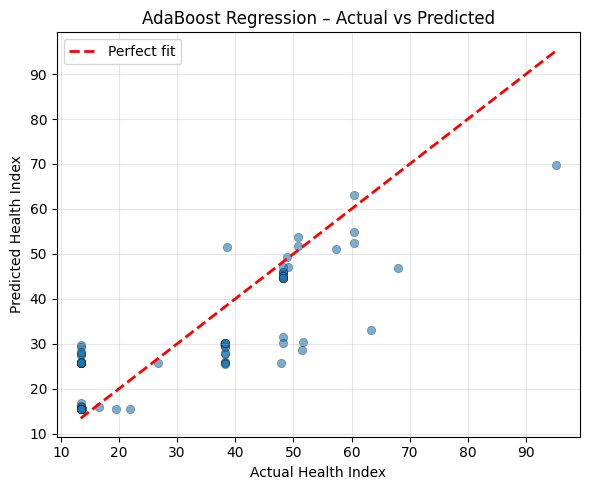

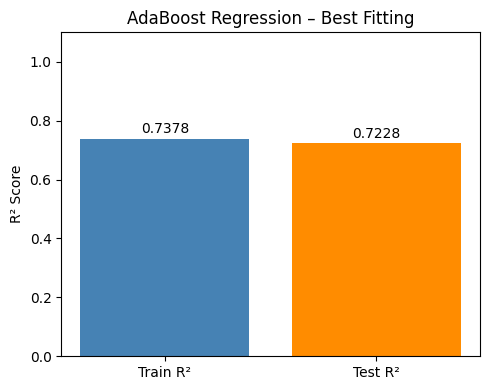

In [19]:
# ── AdaBoost Regression ──
ada_params = {"n_estimators" : [50,100,200,300],
              "learning_rate": [0.01,0.05,0.1,0.5,1]}

grid_ada = GridSearchCV(
    AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3), random_state=42),
    ada_params, scoring='r2', cv=5, n_jobs=-1, verbose=0)
grid_ada.fit(X_train, y_train)
best_ada = grid_ada.best_estimator_
print("Best AdaBoost params:", grid_ada.best_params_)
print("Best CV R²          :", round(grid_ada.best_score_, 4))

yp_te_ada = best_ada.predict(X_test)
yp_tr_ada = best_ada.predict(X_train)

res_ada = evaluate("AdaBoost Regression", y_train, yp_tr_ada, y_test, yp_te_ada)
results.append(res_ada)
parity_plot("AdaBoost Regression", y_test, yp_te_ada)
fitting_bar("AdaBoost Regression", res_ada['Train_R2'], res_ada['Test_R2'], res_ada['Condition'])

## 15. Model 12 – Gradient Boosting Regression

Best GBR params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.6}
Best CV R²     : 0.6768
───────────────────────────────────────────────────────
  Gradient Boosting Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.8140  MAE=5.3168  RMSE=7.5484
  Test   →  R²=0.7706  MAE=6.2629  RMSE=8.8641
  Condition: Best Fitting


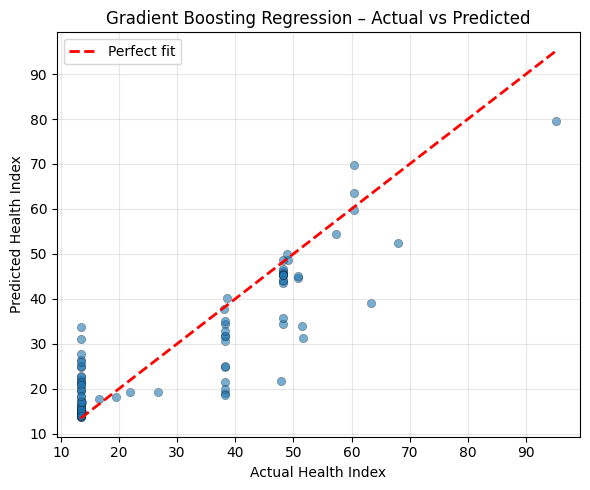

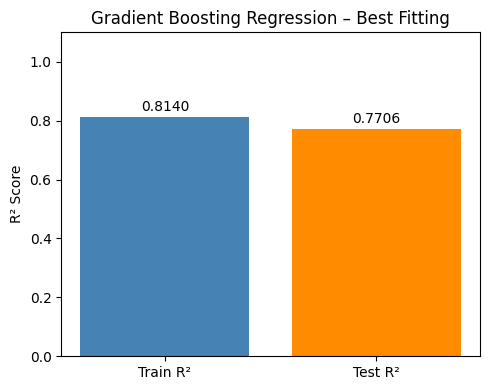

In [20]:
# ── Gradient Boosting Regression ──
gbr_params = {"n_estimators" : [100,200,300],
              "learning_rate": [0.01,0.05,0.1,0.2],
              "max_depth"    : [2,3,4,5],
              "subsample"    : [0.6,0.8,1.0]}

grid_gbr = GridSearchCV(GradientBoostingRegressor(random_state=42),
                        gbr_params, scoring='r2', cv=5, n_jobs=-1, verbose=0)
grid_gbr.fit(X_train, y_train)
best_gbr = grid_gbr.best_estimator_
print("Best GBR params:", grid_gbr.best_params_)
print("Best CV R²     :", round(grid_gbr.best_score_, 4))

yp_te_gbr = best_gbr.predict(X_test)
yp_tr_gbr = best_gbr.predict(X_train)

res_gbr = evaluate("Gradient Boosting Regression", y_train, yp_tr_gbr, y_test, yp_te_gbr)
results.append(res_gbr)
parity_plot("Gradient Boosting Regression", y_test, yp_te_gbr)
fitting_bar("Gradient Boosting Regression", res_gbr['Train_R2'], res_gbr['Test_R2'], res_gbr['Condition'])

## 16. Model 13 – XGBoost Regression

Best XGB params: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 400, 'subsample': 1.0}
Best CV R²     : 0.68
───────────────────────────────────────────────────────
  XGBoost Regression
───────────────────────────────────────────────────────
  Train  →  R²=0.8391  MAE=4.8769  RMSE=7.0204
  Test   →  R²=0.7572  MAE=6.6131  RMSE=9.1196
  Condition: Best Fitting
Top 10 XGB features:
Methane          0.225329
DBDS             0.201066
Interfacial V    0.146329
Acethylene       0.101385
Ethylene         0.065018
Hydrogen         0.059931
Water content    0.043056
Oxigen           0.030450
Ethane           0.029776
Power factor     0.027460


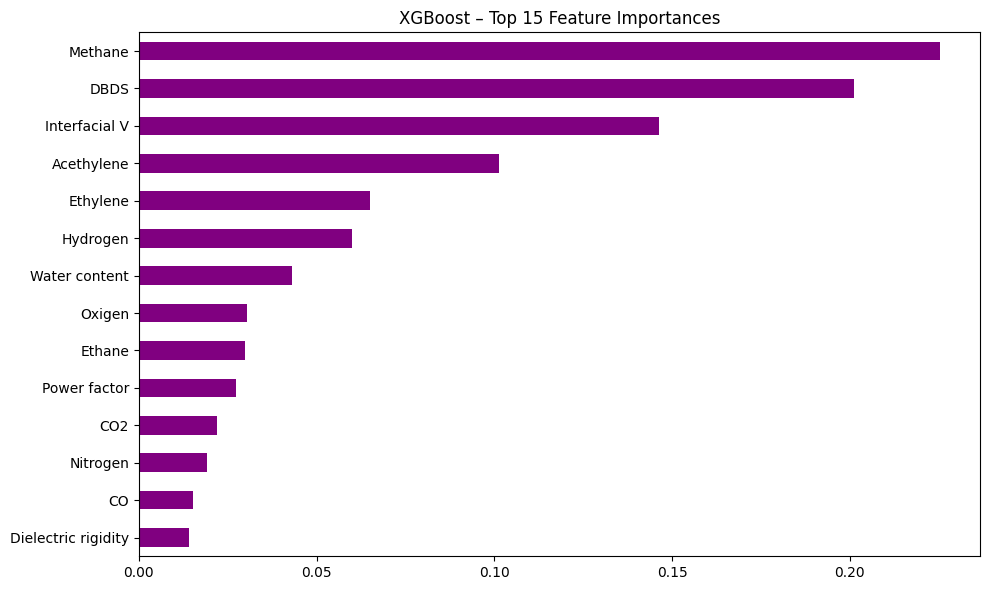

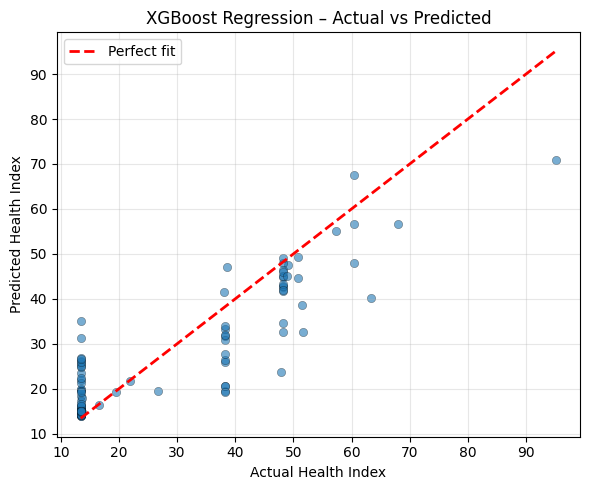

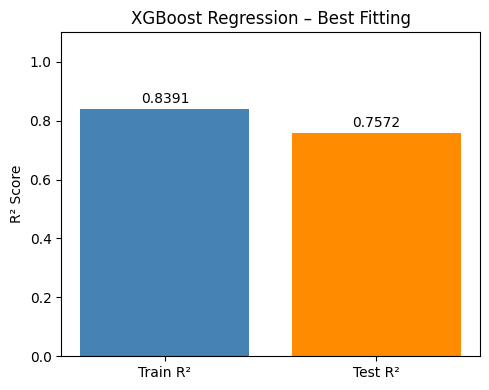

In [21]:
# ── XGBoost Regression ──
xgb_params = {"n_estimators"    : [200,400,600],
              "learning_rate"   : [0.01,0.05,0.1],
              "max_depth"       : [3,5,7],
              "subsample"       : [0.7,0.85,1.0],
              "colsample_bytree": [0.7,0.85,1.0]}

grid_xgb = GridSearchCV(
    XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1),
    xgb_params, scoring='r2', cv=5, n_jobs=-1, verbose=0)
grid_xgb.fit(X_train, y_train)
best_xgb = grid_xgb.best_estimator_
print("Best XGB params:", grid_xgb.best_params_)
print("Best CV R²     :", round(grid_xgb.best_score_, 4))

yp_te_xgb = best_xgb.predict(X_test)
yp_tr_xgb = best_xgb.predict(X_train)

res_xgb = evaluate("XGBoost Regression", y_train, yp_tr_xgb, y_test, yp_te_xgb)
results.append(res_xgb)

fi_xgb = pd.Series(best_xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 10 XGB features:"); print(fi_xgb.head(10).to_string())

plt.figure(figsize=(10,6))
fi_xgb.head(15).sort_values().plot(kind='barh', color='purple')
plt.title("XGBoost – Top 15 Feature Importances"); plt.tight_layout(); plt.show()

parity_plot("XGBoost Regression", y_test, yp_te_xgb)
fitting_bar("XGBoost Regression", res_xgb['Train_R2'], res_xgb['Test_R2'], res_xgb['Condition'])

## 17. Model Comparison & Summary

In [22]:
# ── Summary Table ──
results_df = pd.DataFrame(results).set_index('Model')
results_df.sort_values('Test_R2', ascending=False, inplace=True)
print("="*70)
print("MODEL COMPARISON SUMMARY (sorted by Test R²)")
print("="*70)
print(results_df.to_string())

MODEL COMPARISON SUMMARY (sorted by Test R²)
                              Train_R2  Test_R2  Test_MAE  Test_MSE  Test_RMSE     Condition
Model                                                                                       
Gradient Boosting Regression    0.8140   0.7706    6.2629   78.5727     8.8641  Best Fitting
Decision Tree Regression        0.7475   0.7641    6.2245   80.7777     8.9876  Best Fitting
Random Forest Regression        0.9453   0.7638    6.0380   80.8908     8.9939   Overfitting
XGBoost Regression              0.8391   0.7572    6.6131   83.1669     9.1196  Best Fitting
AdaBoost Regression             0.7378   0.7228    7.2068   94.9344     9.7434  Best Fitting
KNN Regression                  1.0000   0.5332    8.4592  159.8833    12.6445   Overfitting
SVR (RBF)                       0.8042   0.5284    8.2826  161.5153    12.7089   Overfitting
Elastic Net Regression          0.5029   0.5194    9.5501  164.5969    12.8295  Underfitting
Ridge Regression         

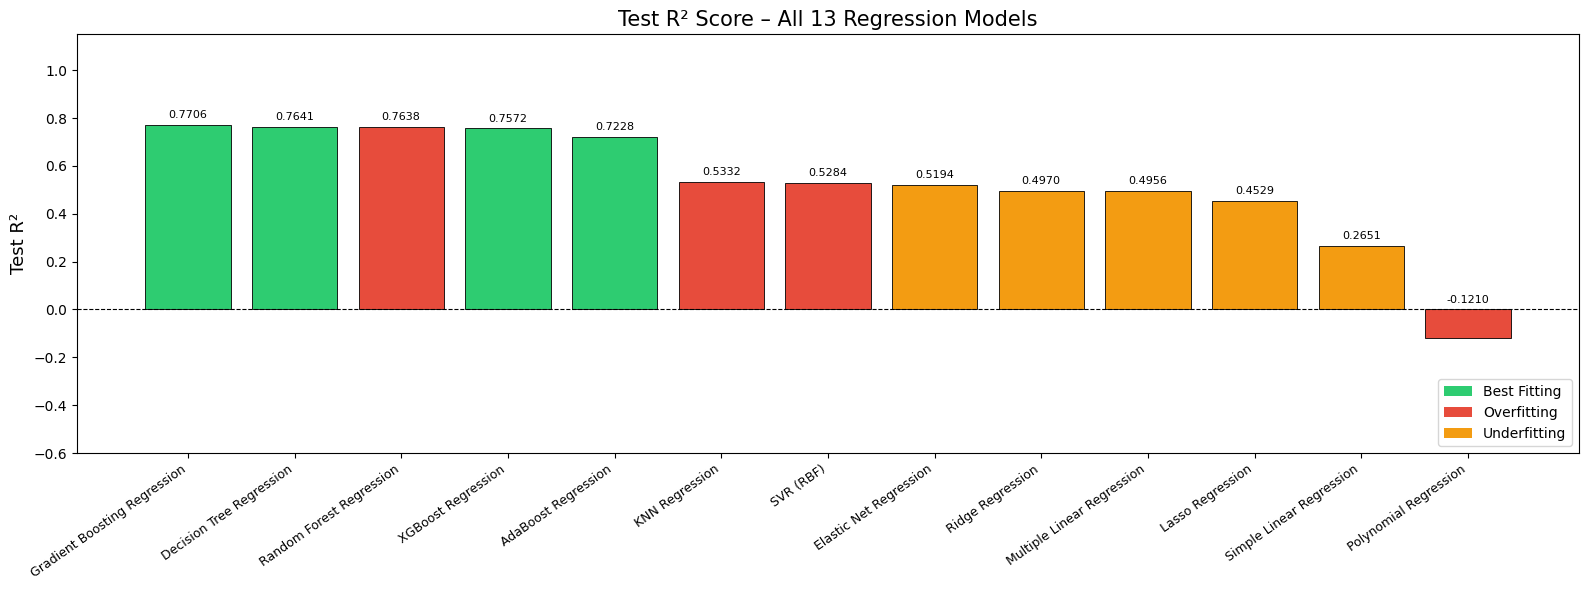

In [23]:
# ── Plot 1: Test R² Bar Chart ──
from matplotlib.patches import Patch

# Clamp Test_R2 to [-0.5, 1.0] for display (very negative R² just means bad model)
plot_r2 = results_df['Test_R2'].clip(lower=-0.5, upper=1.0)

color_map = {'Best Fitting':'#2ecc71', 'Overfitting':'#e74c3c', 'Underfitting':'#f39c12'}
bar_colors = [color_map.get(c, '#aaaaaa') for c in results_df['Condition']]

fig, ax = plt.subplots(figsize=(16, 6))
bars = ax.bar(results_df.index, plot_r2, color=bar_colors, edgecolor='k', linewidth=0.6)
ax.set_ylabel('Test R²', fontsize=13)
ax.set_title('Test R² Score – All 13 Regression Models', fontsize=15)
ax.set_ylim(-0.6, 1.15)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.xticks(rotation=35, ha='right', fontsize=9)
for bar, val in zip(bars, results_df['Test_R2']):
    ypos = max(bar.get_height(), 0) + 0.02
    ax.text(bar.get_x()+bar.get_width()/2, ypos,
            f'{val:.4f}', ha='center', va='bottom', fontsize=8)
legend_elements = [Patch(facecolor=v, label=k) for k,v in color_map.items()]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout(); plt.show()

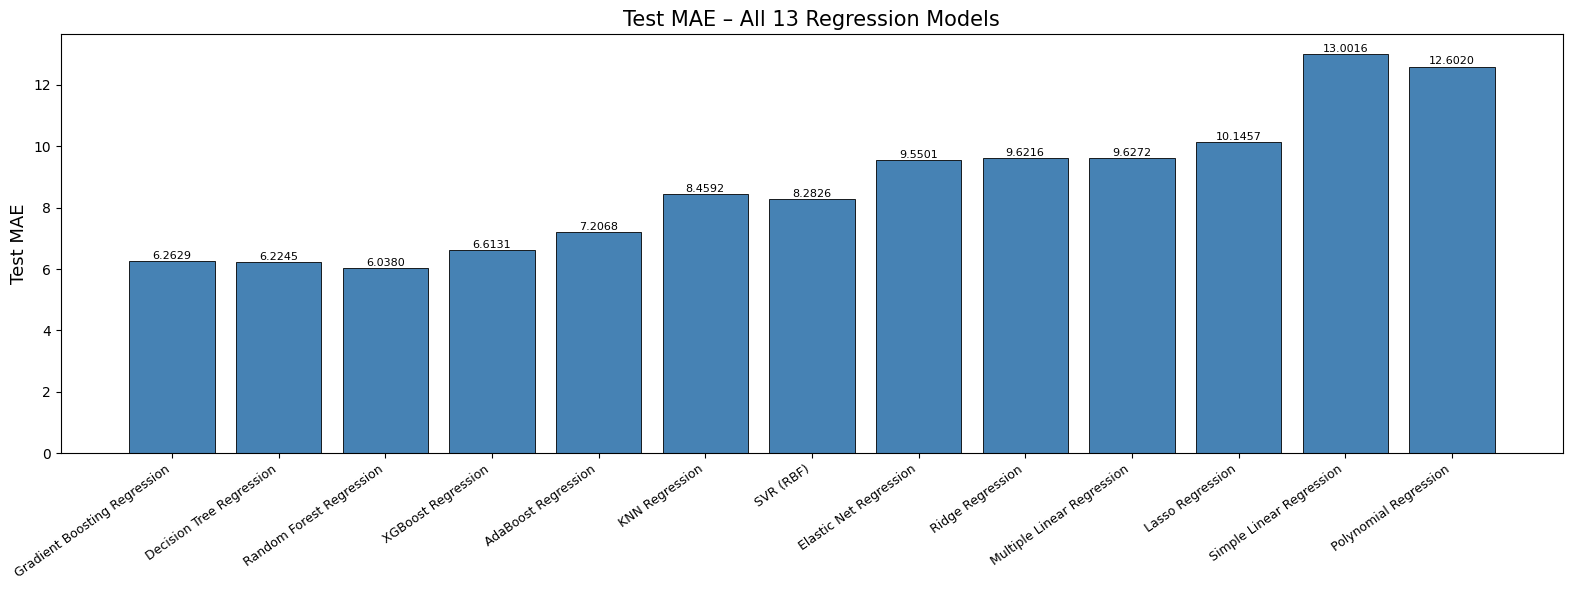

In [24]:
# ── Plot 2: Test MAE Bar Chart ──
fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(results_df.index, results_df['Test_MAE'], color='steelblue', edgecolor='k', linewidth=0.6)
ax.set_ylabel('Test MAE', fontsize=13)
ax.set_title('Test MAE – All 13 Regression Models', fontsize=15)
plt.xticks(rotation=35, ha='right', fontsize=9)
for i,(idx,row) in enumerate(results_df.iterrows()):
    ax.text(i, row['Test_MAE']+0.001, f"{row['Test_MAE']:.4f}",
            ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

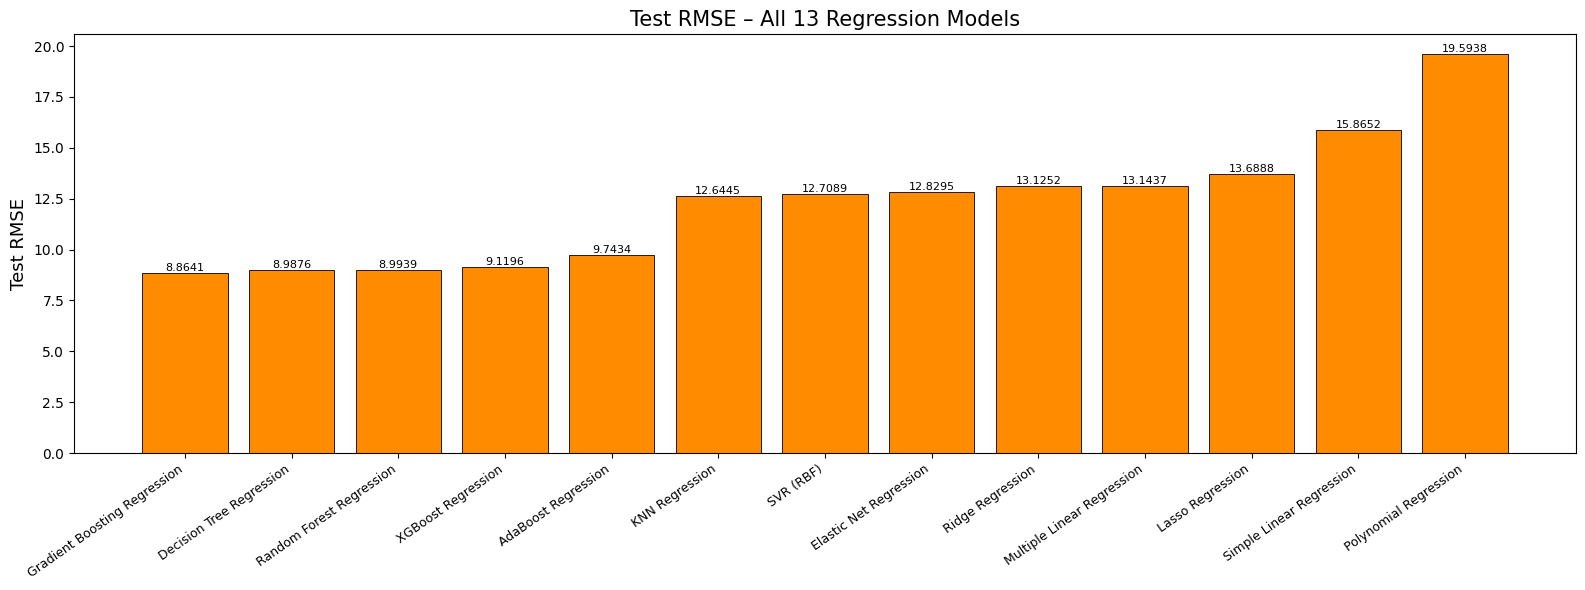

In [25]:
# ── Plot 3: Test RMSE Bar Chart ──
fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(results_df.index, results_df['Test_RMSE'], color='darkorange', edgecolor='k', linewidth=0.6)
ax.set_ylabel('Test RMSE', fontsize=13)
ax.set_title('Test RMSE – All 13 Regression Models', fontsize=15)
plt.xticks(rotation=35, ha='right', fontsize=9)
for i,(idx,row) in enumerate(results_df.iterrows()):
    ax.text(i, row['Test_RMSE']+0.001, f"{row['Test_RMSE']:.4f}",
            ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

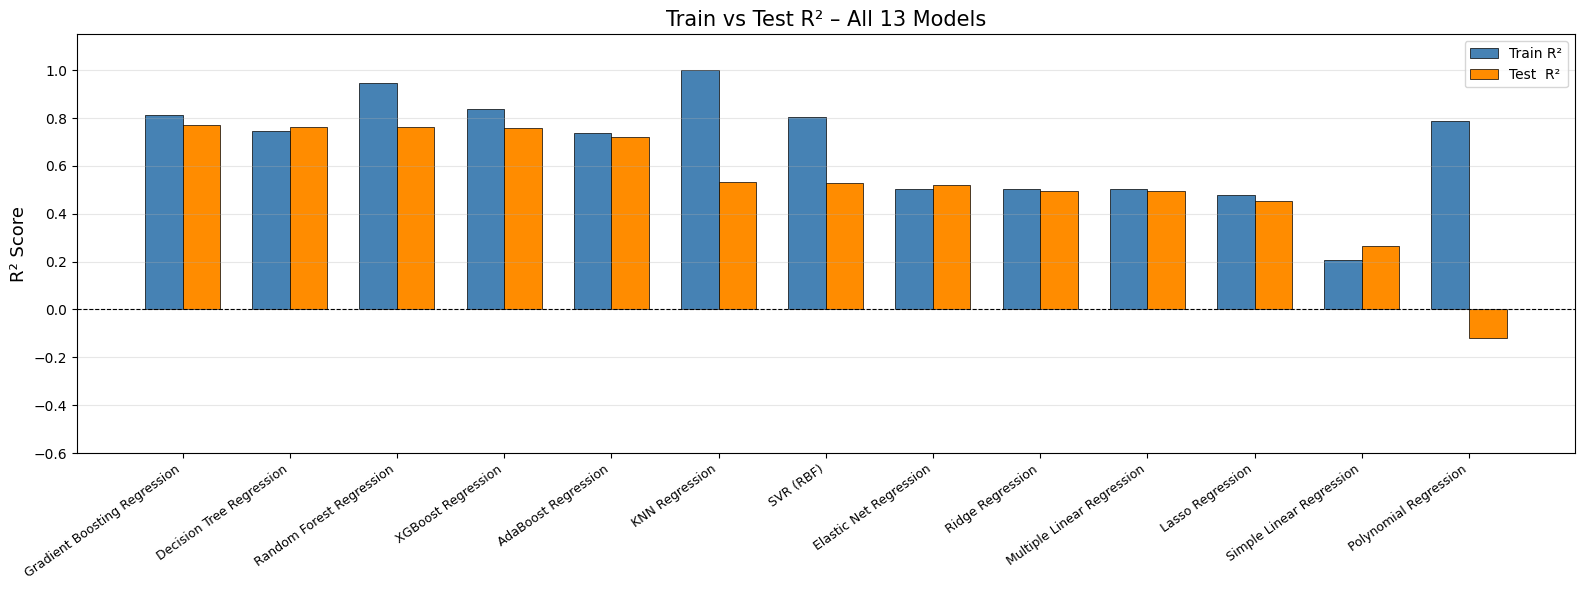

In [26]:
# ── Plot 4: Train vs Test R² Grouped Bar ──
x = np.arange(len(results_df))
width = 0.35
fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(x-width/2, results_df['Train_R2'].clip(-0.5,1), width, label='Train R²',
       color='steelblue', edgecolor='k', linewidth=0.5)
ax.bar(x+width/2, results_df['Test_R2'].clip(-0.5,1),  width, label='Test  R²',
       color='darkorange', edgecolor='k', linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(results_df.index, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('R² Score', fontsize=13)
ax.set_title('Train vs Test R² – All 13 Models', fontsize=15)
ax.set_ylim(-0.6, 1.15)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

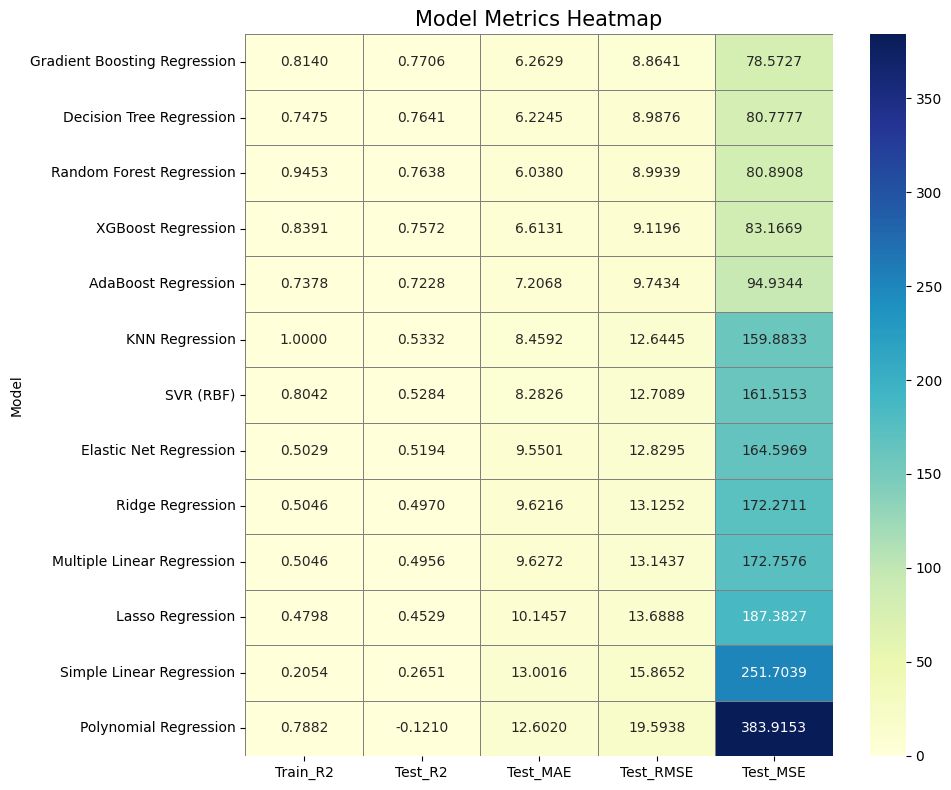

In [27]:
# ── Plot 5: Metrics Heatmap ──
metric_cols = ['Train_R2','Test_R2','Test_MAE','Test_RMSE','Test_MSE']
plt.figure(figsize=(10,8))
sns.heatmap(results_df[metric_cols].astype(float),
            annot=True, fmt='.4f', cmap='YlGnBu',
            linewidths=0.5, linecolor='gray')
plt.title('Model Metrics Heatmap', fontsize=15)
plt.tight_layout(); plt.show()

In [28]:
# ── Final Ranking ──
print("\n" + "="*65)
print("FINAL RANKING (by Test R²)")
print("="*65)
rank_df = results_df[['Test_R2','Test_MAE','Test_RMSE','Condition']].copy()
rank_df.insert(0, 'Rank', range(1, len(rank_df)+1))
print(rank_df.to_string())

best_model_name = results_df.index[0]
print(f"\n🏆  Best Model : {best_model_name}")
print(f"    Test R²   : {results_df.loc[best_model_name, 'Test_R2']}")
print(f"    Test MAE  : {results_df.loc[best_model_name, 'Test_MAE']}")
print(f"    Test RMSE : {results_df.loc[best_model_name, 'Test_RMSE']}")
print(f"    Condition : {results_df.loc[best_model_name, 'Condition']}")


FINAL RANKING (by Test R²)
                              Rank  Test_R2  Test_MAE  Test_RMSE     Condition
Model                                                                         
Gradient Boosting Regression     1   0.7706    6.2629     8.8641  Best Fitting
Decision Tree Regression         2   0.7641    6.2245     8.9876  Best Fitting
Random Forest Regression         3   0.7638    6.0380     8.9939   Overfitting
XGBoost Regression               4   0.7572    6.6131     9.1196  Best Fitting
AdaBoost Regression              5   0.7228    7.2068     9.7434  Best Fitting
KNN Regression                   6   0.5332    8.4592    12.6445   Overfitting
SVR (RBF)                        7   0.5284    8.2826    12.7089   Overfitting
Elastic Net Regression           8   0.5194    9.5501    12.8295  Underfitting
Ridge Regression                 9   0.4970    9.6216    13.1252  Underfitting
Multiple Linear Regression      10   0.4956    9.6272    13.1437  Underfitting
Lasso Regression        